# LatentJam: algorithm and audio-weight comparison

**Recommendation:** average linkage, 75% audio / 25% metadata, cosine cut 0.75, minimum region size 4. It creates 35 regions containing 898 of 1,107 tracks. Mean-shift is more stable, but did not demonstrate the strongest paired acoustic improvement. This is an exploratory recommendation, not musical ground truth.

## Context & Methods

440 outputs from 220 parameter sets. Actual Kotlin fusion/centering and naming. CLAP on local excerpts: 107 development tracks, 145 artist-disjoint holdout tracks. Five algorithm families; fixed family candidates selected before holdout inspection.

### Key assumptions

At least 55% library coverage, 45% development audit coverage and 8–45 final regions. Same-artist-only groups cannot be scored by the cross-artist metric. Similarity ranks are not correctness percentages. Available audio is not a random library sample. Comparison intervals resample artists, with approximate adjustment for four family comparisons. See report-public.md / the repository report for full caveats and source provenance.

In [1]:
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
s = json.loads(Path('public-results.json').read_text())
assert s['baseline_exact'] and s['population'] == 1107
assert s['raw_settings'] == 220 and s['output_settings'] == 440
assert s['development_tracks'] + s['holdout_tracks'] == 252
assert s['audit_checks']['same_track_other_excerpt_median_percentile'] >= .8
print('Aggregate and source-replay checks passed.')

Aggregate and source-replay checks passed.


## Results

Changes below compare a candidate against baseline on their common held-out anchors. Each row can have a different denominator. The intervals do not establish listener correctness.

In [2]:
m = pd.DataFrame(s['matched_comparisons']['family_vs_baseline'])
h = {v['name']: v for v in s['holdout']}
t = pd.DataFrame([{'Candidate':r['name'], 'Regions':h[r['name']]['regions'], 'Inside':h[r['name']]['assigned'], 'Outside':1107-h[r['name']]['assigned'], 'Common anchors':r['anchors'], 'Gain (rank points)':round(100*r['difference'],2), 'Adjusted interval':str([round(100*v,2) for v in r['artist_bootstrap_ci98p75_four_comparisons']])} for r in s['matched_comparisons']['family_vs_baseline']])
assert ((t['Inside'] + t['Outside']) == 1107).all()
display(t)

,Candidate,Regions,Inside,Outside,Common anchors,Gain (rank points),Adjusted interval
0,a75-average-0p75-own,35,898,209,97,4.37,"[0.33, 8.52]"
1,a50-compact-0p55-own,37,807,300,71,2.68,"[-0.81, 6.49]"
2,a75-dms-10-own,15,745,362,69,1.41,"[-2.8, 5.53]"
3,a60-kmeans-24-own,26,1018,89,114,2.75,"[-1.56, 7.34]"


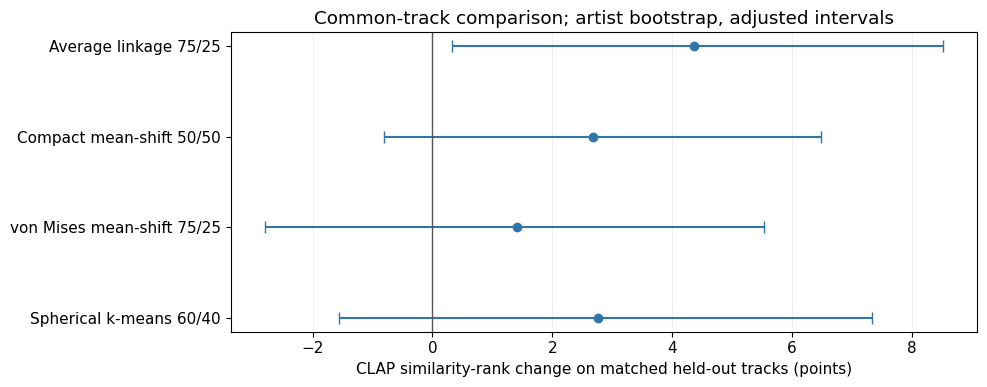

In [3]:
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11})
fig, ax = plt.subplots(figsize=(10,4))
labels = ['Average linkage 75/25','Compact mean-shift 50/50','von Mises mean-shift 75/25','Spherical k-means 60/40']
for i,r in m.iterrows():
    mid=100*r['difference']; lo,hi=np.array(r['artist_bootstrap_ci98p75_four_comparisons'])*100
    ax.errorbar(mid,i,xerr=[[mid-lo],[hi-mid]],fmt='o',capsize=4,color='#3275a8')
ax.axvline(0,color='#555',lw=1); ax.set_yticks(range(len(m)),labels); ax.invert_yaxis()
ax.set_xlabel('CLAP similarity-rank change on matched held-out tracks (points)')
ax.set_title('Common-track comparison; artist bootstrap, adjusted intervals')
ax.grid(axis='x',alpha=.2); fig.tight_layout(); plt.show()

## Stability

Raw clusters refitted after deleting 10% of the library for seeds 3, 17, 41. Noise represented by separate singletons; final names are not evaluated here.

In [4]:
z=pd.DataFrame(s['stability']); display(z.groupby('key')['ari_noise_as_singletons'].agg(['min','max']).round(3))

,min,max
key,,
a25-kmeans-16,0.706,0.777
a50-compact-0p55,0.588,0.912
a50-dms-8p5,0.936,0.950
a60-kmeans-24,0.643,0.681
a75-average-0p75,0.670,0.747
a75-dms-10,0.917,0.937


## Takeaways

Average linkage 75/25 improves matched acoustic cohesion and keeps 898 tracks. Directional mean-shift 75/25 κ=10 keeps 745 and is more stable, but its apparent superiority on an unmatched average does not survive fair comparison. A precise globally optimal weight is not established; ratios above 75% were not searched. Some mixed regions remain. Production code and map coordinates are unchanged.

Sources: frozen 13 October owner snapshot; exact Kotlin baseline replay; local CLAP revision a0b4534a14f58e20944452dff00a22a06ce629d1; protocol.json and refinement-protocol.json. No MOSS ratings used. Raw private inputs are kept outside Git; public-results.json contains aggregate outputs only.